In [1]:
pip install transformers datasets torch scikit-learn pandas -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.2/491.2 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 78.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 51.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 33.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 68.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 

In [2]:
!pip install transformers[torch] -q

Some weights of RobertaModel were not initialized from the model checkpoint at vinai/phobert-base-v2 and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch 1 | Train Loss: 1.0968, Acc: 0.4158 | Val Loss: 1.0900, Acc: 0.5479


Epoch 2 | Train Loss: 0.9205, Acc: 0.6646 | Val Loss: 0.6629, Acc: 0.8204


Epoch 3 | Train Loss: 0.5478, Acc: 0.8328 | Val Loss: 0.4150, Acc: 0.8630


Epoch 4 | Train Loss: 0.3832, Acc: 0.8817 | Val Loss: 0.4253, Acc: 0.8584


Epoch 5 | Train Loss: 0.3110, Acc: 0.9091 | Val Loss: 0.4440, Acc: 0.8615

📊 Test Set Evaluation Results:
              precision    recall  f1-score   support

         neg     0.8264    0.8623    0.8440       138
         neu     0.8987    0.8068    0.8503       264
         pos     0.8375    0.9062    0.8705       256

    accuracy                         0.8571       658
   macro avg     0.8542    0.8585    0.8549       658
weighted avg     0.8598    0.8571    0.8568       658



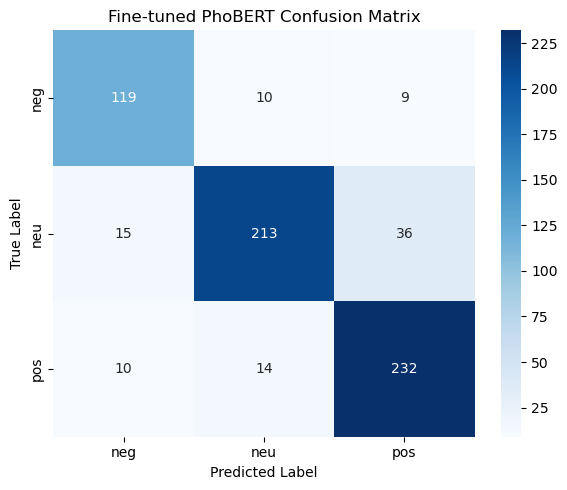

In [1]:
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_scheduler
from torch.optim import AdamW
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
from tqdm import tqdm
import seaborn as sns
import matplotlib.pyplot as plt

# ========== STEP 1: Load & Preprocess Data ==========

df = pd.read_csv('V5_data.csv')

# Label mapping (neg: 0, neu: 1, pos: 2)
label_map = {'neg': 0, 'neu': 1, 'pos': 2}
df['label'] = df['Sentiment'].map(label_map)

# Split: 80% train, 10% val, 10% test
train_texts, temp_texts, train_labels, temp_labels = train_test_split(
    df['Segmented_Title'], df['label'],
    test_size=0.2, stratify=df['label'], random_state=42
)

val_texts, test_texts, val_labels, test_labels = train_test_split(
    temp_texts, temp_labels,
    test_size=0.5, stratify=temp_labels, random_state=42
)

# ========== STEP 2: Dataset and Tokenization ==========

tokenizer = AutoTokenizer.from_pretrained("vinai/phobert-base-v2", use_fast=False)

class SentimentDataset(Dataset):
    def __init__(self, texts, labels):
        self.encodings = tokenizer(
            texts.tolist(), padding=True, truncation=True,
            max_length=256, return_tensors="pt"
        )
        self.labels = torch.tensor(labels.tolist(), dtype=torch.long)

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = self.labels[idx]
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = SentimentDataset(train_texts, train_labels)
val_dataset = SentimentDataset(val_texts, val_labels)
test_dataset = SentimentDataset(test_texts, test_labels)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16)
test_loader = DataLoader(test_dataset, batch_size=16)

# ========== STEP 3: Custom PhoBERT Classifier ==========

class CustomPhoBERTClassifier(torch.nn.Module):
    def __init__(self, phobert, class_weights=None):
        super().__init__()
        self.phobert = phobert
        self.dropout = torch.nn.Dropout(0.3)
        
        self.mlp = torch.nn.Sequential(
            torch.nn.Linear(768 * 4, 1024),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.3),   # Increase dropout slightly
        
            torch.nn.Linear(1024, 512),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.3),
        
            torch.nn.Linear(512, 256),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.3),
        
            torch.nn.Linear(256, 128),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.3),
        
            torch.nn.Linear(128, 3)
        )
        
        self.loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights)

    def forward(self, input_ids, attention_mask, labels=None):
        outputs = self.phobert(input_ids=input_ids, attention_mask=attention_mask)
        hidden_states = outputs.hidden_states[-4:]
        cls_output = torch.cat([h[:, 0, :] for h in hidden_states], dim=-1)
        cls_output = self.dropout(cls_output)
        logits = self.mlp(cls_output)
        loss = None
        if labels is not None:
            loss = self.loss_fn(logits, labels)
        return {"loss": loss, "logits": logits}

    def save_pretrained(self, save_directory):
        import os
        os.makedirs(save_directory, exist_ok=True)
        self.phobert.save_pretrained(save_directory)
        torch.save(self.state_dict(), os.path.join(save_directory, "pytorch_model.bin"))

# ========== STEP 4: Model, Optimizer, Scheduler ==========

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class_weights_np = compute_class_weight(
    'balanced', classes=np.unique(train_labels), y=train_labels
)
class_weights = torch.tensor(class_weights_np, dtype=torch.float).to(device)

phobert = AutoModel.from_pretrained("vinai/phobert-base-v2", output_hidden_states=True)
model = CustomPhoBERTClassifier(phobert, class_weights=class_weights).to(device)

# Optional: warm-up - freeze PhoBERT at the beginning
for param in model.phobert.parameters():
    param.requires_grad = False

optimizer = AdamW(model.parameters(), lr=2e-5, eps=1e-8)
num_epochs = 5
num_training_steps = len(train_loader) * num_epochs
lr_scheduler = get_scheduler("linear", optimizer=optimizer, num_warmup_steps=0, num_training_steps=num_training_steps)

# ========== STEP 5: Training Loop ==========

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

for epoch in range(num_epochs):
    model.train()
    running_train_loss = 0.0
    correct_train = 0
    total_train = 0

    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}", leave=False):
        batch = {k: v.to(device) for k, v in batch.items() if k != 'token_type_ids'}
        outputs = model(**batch)
        loss = outputs['loss']
        logits = outputs['logits']
        preds = torch.argmax(logits, dim=1)

        correct_train += (preds == batch['labels']).sum().item()
        total_train += batch['labels'].size(0)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        lr_scheduler.step()
        optimizer.zero_grad()
        running_train_loss += loss.item()

    avg_train_loss = running_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    train_acc = correct_train / total_train
    train_accuracies.append(train_acc)

    # ====== Validation ======
    model.eval()
    running_val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for batch in val_loader:
            batch = {k: v.to(device) for k, v in batch.items() if k != 'token_type_ids'}
            outputs = model(**batch)
            val_loss = outputs['loss']
            logits = outputs['logits']
            preds = torch.argmax(logits, dim=1)

            correct_val += (preds == batch['labels']).sum().item()
            total_val += batch['labels'].size(0)
            running_val_loss += val_loss.item()

    avg_val_loss = running_val_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    val_acc = correct_val / total_val
    val_accuracies.append(val_acc)

    print(f"Epoch {epoch+1} | Train Loss: {avg_train_loss:.4f}, Acc: {train_acc:.4f} | Val Loss: {avg_val_loss:.4f}, Acc: {val_acc:.4f}")

    # Unfreeze after first epoch
    if epoch == 0:
        for param in model.phobert.parameters():
            param.requires_grad = True

# ========== STEP 6: Evaluation on Test Set ==========

model.eval()
all_preds, all_labels_eval = [], []

with torch.no_grad():
    for batch in test_loader:
        batch = {k: v.to(device) for k, v in batch.items() if k != 'token_type_ids'}
        outputs = model(**batch)
        logits = outputs['logits']
        preds = torch.argmax(logits, dim=-1)
        all_preds.extend(preds.cpu().numpy())
        all_labels_eval.extend(batch['labels'].cpu().numpy())

# ===== Classification Report =====
target_names = ['neg', 'neu', 'pos']
print("\n📊 Test Set Evaluation Results:")
print(classification_report(all_labels_eval, all_preds, target_names=target_names, digits=4))

# ===== Confusion Matrix =====
cm = confusion_matrix(all_labels_eval, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Fine-tuned PhoBERT Confusion Matrix')
plt.tight_layout()
plt.savefig('phoBERT_confusion_matrix.png')
plt.show()


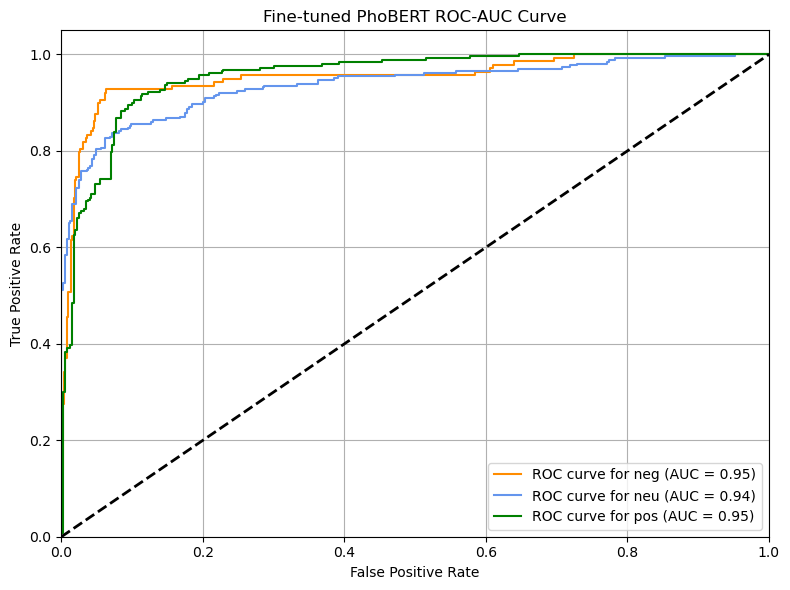

In [2]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

# Class labels
target_names = ['neg', 'neu', 'pos']
n_classes = len(target_names)

# Get predicted probabilities from the test set
model.eval()
all_logits = []
all_labels_test = []

with torch.no_grad():
    for batch in test_loader:
        batch = {k: v.to(device) for k, v in batch.items() if k != 'token_type_ids'}
        outputs = model(**batch)
        logits = outputs['logits']
        all_logits.append(logits.cpu())
        all_labels_test.extend(batch['labels'].cpu().numpy())

# Concatenate all logits and apply softmax
all_logits = torch.cat(all_logits, dim=0)
all_probs = torch.softmax(all_logits, dim=1).numpy()

# One-hot encode true labels
y_true_bin = label_binarize(all_labels_test, classes=[0, 1, 2])  # 3 classes

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], all_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC curves
plt.figure(figsize=(8, 6))
colors = ['darkorange', 'cornflowerblue', 'green']
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], color=colors[i],
             label=f"ROC curve for {target_names[i]} (AUC = {roc_auc[i]:.2f})")

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Fine-tuned PhoBERT ROC-AUC Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.savefig('phoBERT_ROC.png')
plt.show()


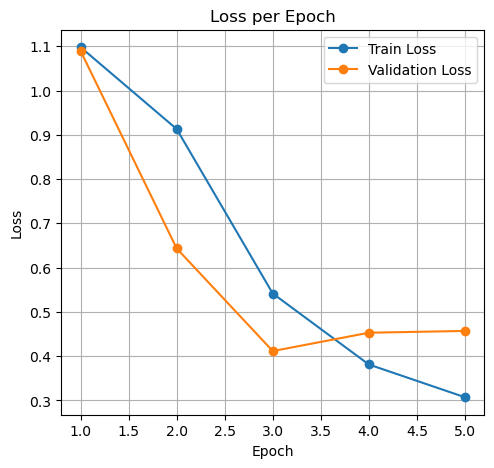

In [4]:
epochs = range(1, num_epochs + 1)

# Plot Loss
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label="Train Loss", marker='o')
plt.plot(epochs, val_losses, label="Validation Loss", marker='o')
plt.title("Loss per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

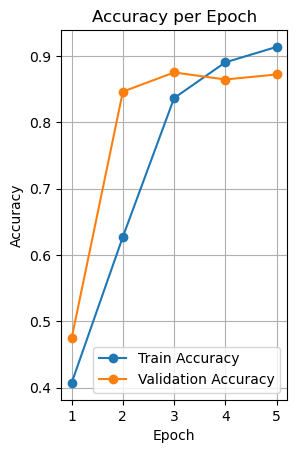

In [5]:
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, label="Train Accuracy", marker='o')
plt.plot(epochs, val_accuracies, label="Validation Accuracy", marker='o')
plt.title("Accuracy per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

In [5]:
# Reset test_texts index to align with test_labels
test_texts_reset = test_texts.reset_index(drop=True)
test_labels_reset = test_labels.reset_index(drop=True)

# Ensure lengths match
assert len(all_preds) == len(test_labels_reset) == len(test_texts_reset), "Length mismatch!"

# Find misclassified examples
misclassified = []

for i in range(len(all_preds)):
    true_label = test_labels_reset[i]
    pred_label = all_preds[i]
    if true_label != pred_label:
        misclassified.append({
            "text": test_texts_reset[i],
            "true_label": target_names[true_label],
            "predicted_label": target_names[pred_label]
        })

# Convert to DataFrame
misclassified_df = pd.DataFrame(misclassified)

# Optional: show first few
print(misclassified_df.head())


                                                text true_label  \
0  iShare ETF thay_đổi chỉ_số tham_chiếu , thị_tr...        neg   
1          Thêm hàng_rào chống tội_phạm thẻ từ 1 - 7        pos   
2  VCH : Công_bố thông_tin kết_quả phát_hành riên...        neu   
3                  Cửa nào cho VietinBank tăng vốn ?        neu   
4  Gần 60 . 000 tỷ nợ vay của Novaland gồm những ...        neg   

  predicted_label  
0             neu  
1             neu  
2             pos  
3             pos  
4             neu  


In [6]:
misclassified_df.to_csv("misclassified_examples.csv", index=False)

In [6]:
# Define your model save path
model_save_path = "phobert_finance_news_sentiment_classification"

# Save the full model including head
model.save_pretrained(model_save_path)

# Save the tokenizer as well
tokenizer.save_pretrained(model_save_path)


('phobert_finance_news_sentiment_classification\\tokenizer_config.json',
 'phobert_finance_news_sentiment_classification\\special_tokens_map.json',
 'phobert_finance_news_sentiment_classification\\vocab.txt',
 'phobert_finance_news_sentiment_classification\\bpe.codes',
 'phobert_finance_news_sentiment_classification\\added_tokens.json')

In [7]:
import zipfile
import os

def zip_folder(folder_path, output_path):
    with zipfile.ZipFile(output_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        for root, _, files in os.walk(folder_path):
            for file in files:
                full_path = os.path.join(root, file)
                relative_path = os.path.relpath(full_path, start=folder_path)
                zipf.write(full_path, arcname=relative_path)

# Zip the saved model directory
zip_folder("phobert_finance_news_sentiment_classification", "phobert_model.zip")


In [ ]:
!pip install huggingface_hub
!huggingface-cli login


    _|    _|  _|    _|    _|_|_|    _|_|_|  _|_|_|  _|      _|    _|_|_|      _|_|_|_|    _|_|      _|_|_|  _|_|_|_|
    _|    _|  _|    _|  _|        _|          _|    _|_|    _|  _|            _|        _|    _|  _|        _|
    _|_|_|_|  _|    _|  _|  _|_|  _|  _|_|    _|    _|  _|  _|  _|  _|_|      _|_|_|    _|_|_|_|  _|        _|_|_|
    _|    _|  _|    _|  _|    _|  _|    _|    _|    _|    _|_|  _|    _|      _|        _|    _|  _|        _|
    _|    _|    _|_|      _|_|_|    _|_|_|  _|_|_|  _|      _|    _|_|_|      _|        _|    _|    _|_|_|  _|_|_|_|

    To log in, `huggingface_hub` requires a token generated from https://huggingface.co/settings/tokens .
Enter your token (input will not be visible): 
Add token as git credential? (Y/n) n
Token is valid (permission: write).
The token `colab` has been saved to /root/.cache/huggingface/stored_tokens
Your token has been saved to /root/.cache/huggingface/token
Login successful.
The current active token is: `colab`


In [ ]:
from huggingface_hub import HfApi

api = HfApi()
# Assuming your Hugging Face username or organization is "your-username"
repo_id = "Boon0710/phoBert-based-financial-news-sentiment-classification"
api.create_repo(repo_id=repo_id, private=False)

RepoUrl('https://huggingface.co/Boon0710/phoBert-based-financial-news-sentiment-classification', endpoint='https://huggingface.co', repo_type='model', repo_id='Boon0710/phoBert-based-financial-news-sentiment-classification')

In [ ]:
model.phobert.push_to_hub(repo_id)
tokenizer.push_to_hub(repo_id)

model.safetensors:   0%|          | 0.00/540M [00:00<?, ?B/s]

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

CommitInfo(commit_url='https://huggingface.co/Boon0710/phoBert-based-financial-news-sentiment-classification/commit/db6f020946399429f80c623c82fcf122bc1949ca', commit_message='Upload tokenizer', commit_description='', oid='db6f020946399429f80c623c82fcf122bc1949ca', pr_url=None, repo_url=RepoUrl('https://huggingface.co/Boon0710/phoBert-based-financial-news-sentiment-classification', endpoint='https://huggingface.co', repo_type='model', repo_id='Boon0710/phoBert-based-financial-news-sentiment-classification'), pr_revision=None, pr_num=None)